DATA CLEANING

In [ ]:

import ast
import pandas as pd

# read the files and instantly drop movies with no imdb score
netflix_raw = pd.read_csv("titles.csv").dropna(subset=["imdb_score"]).copy()

# kaggle stores lists as weird text strings like "['Comedy']", this converts them back
def fix_text_lists(val):
    if pd.notna(val) and str(val).startswith("["):
        return ast.literal_eval(val)
    return []

netflix_raw["genres"] = netflix_raw["genres"].apply(fix_text_lists)
netflix_raw["production_countries"] = netflix_raw["production_countries"].apply(fix_text_lists)

# patch up the missing data
# movies have 0 seasons, so force them to integers
netflix_raw["seasons"] = netflix_raw["seasons"].fillna(0).astype(int)

# label blank age ratings so we don't lose the row
netflix_raw["age_certification"] = netflix_raw["age_certification"].fillna("Unrated")

# fill missing runtimes with the median to avoid skewing our graphs
netflix_raw["runtime"] = netflix_raw["runtime"].fillna(netflix_raw["runtime"].median())

# load the cast and crew data
credits_raw = pd.read_csv("credits.csv")

print("cleaning finished.")
print(f"ready for analysis. total rows: {netflix_raw.shape[0]}")

cleaning finished.
ready for analysis. total rows: 5368


sairam

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

sns.set_theme(style="whitegrid")

# just checking everything loaded
print("imports done")

imports done


In [ ]:
netflix = pd.read_csv("titles.csv")

# this caused me a bug earlier - 'Movie' and 'MOVIE' were both in the data
# so doing upper() to fix that
netflix["type"] = netflix["type"].str.upper()

print("dataset size:", netflix.shape)
# just peeking at first few rows
netflix.head(3)

dataset size: (5850, 15)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,1945,TV-MA,51,['documentation'],['US'],1.0,NaN,NaN,NaN,0.600,NaN
1,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,114,"['drama', 'crime']",['US'],NaN,tt0075314,8.2,808582.0,40.965,8.179
2,tm154986,Deliverance,MOVIE,Intent on seeing the Cahulawassee River before...,1972,R,109,"['drama', 'action', 'thriller', 'european']",['US'],NaN,tt0068473,7.7,107673.0,10.010,7.300


top 10:
countries_fixed
US    35.585172
IN     9.528186
GB     6.188725
JP     4.396446
FR     3.799020
KR     3.492647
CA     3.354779
ES     3.232230
DE     2.129289
MX     1.930147
Name: count, dtype: float64


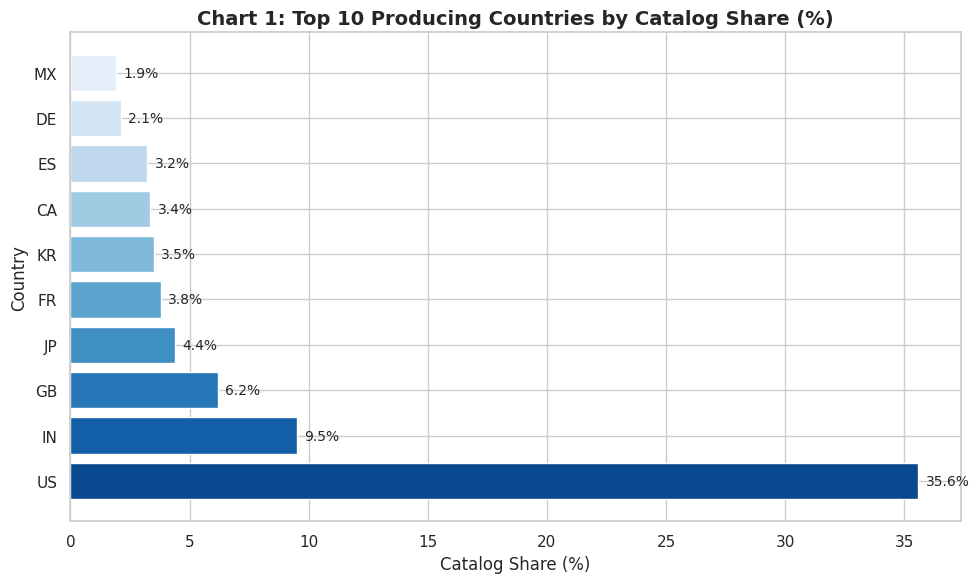

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import ast

# so the production_countries column is really annoying
# it looks like ['US', 'IN'] but its actually stored as a plain string
# took me a while to figure this out

def fix_country_col(entry):
    # empty or missing - just skip
    if pd.isna(entry) or entry == "" or entry == "[]":
        return []

    try:
        # ast converts the string into an actual python list
        got = ast.literal_eval(entry)
        return got
    except:
        # if that fails i'll just remove the brackets manually and split
        temp = entry.replace("[", "").replace("]", "")
        temp = temp.replace("'", "").replace('"', "")
        each = temp.split(",")
        result = []
        for x in each:
            x = x.strip()
            if x != "":
                result.append(x)
        return result

netflix["countries_fixed"] = netflix["production_countries"].apply(fix_country_col)

# explode makes one row per country instead of a list in one row
rows_by_country = netflix.explode("countries_fixed")
rows_by_country = rows_by_country[rows_by_country["countries_fixed"].notna()]
rows_by_country = rows_by_country[rows_by_country["countries_fixed"] != ""]

# how many times each country shows up
how_many = rows_by_country["countries_fixed"].value_counts()
top_countries = how_many.head(10)

# converting to percent
all_rows = len(rows_by_country)
share = (top_countries / all_rows) * 100

print("top 10:")
print(share)

# ---------- plot ----------
fig, ax = plt.subplots(figsize=(10, 6))

# blues go dark to light - darker = more share
c = sns.color_palette("Blues_r", 10)
ax.barh(top_countries.index, share.values, color=c)

# add the % number at end of each bar
for i in range(len(share)):
    v = share.values[i]
    ax.text(v + 0.3, i, str(round(v, 1)) + "%", va="center", fontsize=10)

ax.set_title("Chart 1: Top 10 Producing Countries by Catalog Share (%)", fontsize=14, fontweight="bold")
ax.set_xlabel("Catalog Share (%)")
ax.set_ylabel("Country")

plt.tight_layout()
plt.show()

how many have a rating: 3231
unique ratings found: ['TV-MA' 'R' 'PG' 'TV-14' 'PG-13' 'TV-PG' 'TV-Y' 'TV-G' 'TV-Y7' 'G'
 'NC-17']


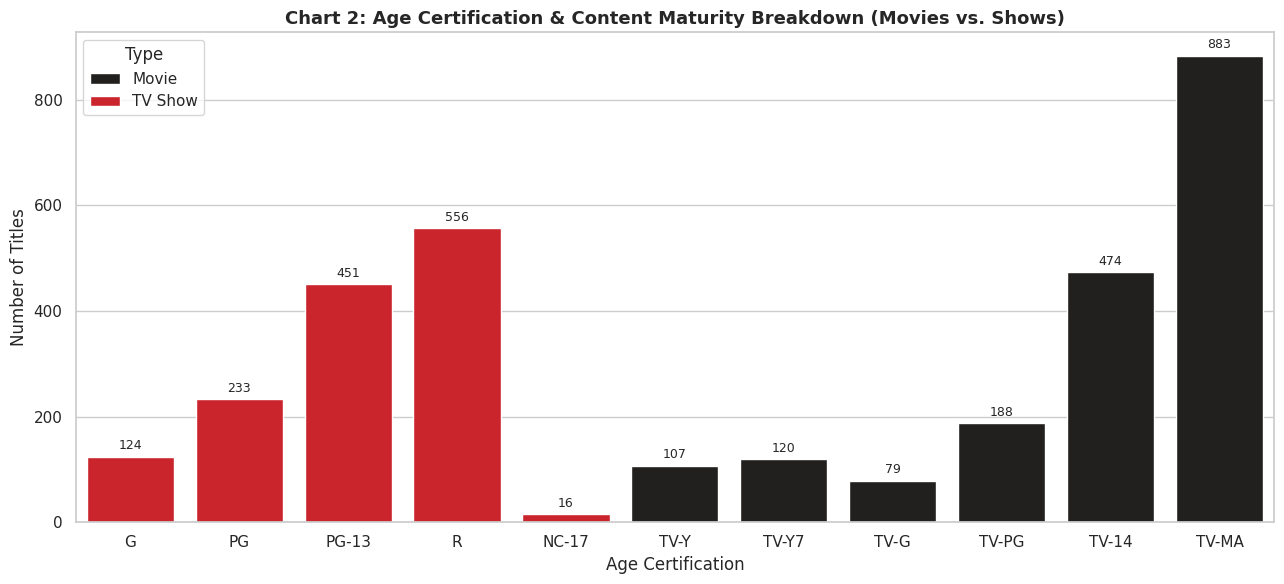

In [ ]:
# first removing rows where age rating is missing
# tried using fillna earlier but that just added NaN text into the chart which looked bad
has_rating = netflix[netflix["age_certification"].notna()].copy()
has_rating = has_rating[has_rating["age_certification"].str.strip() != ""]

print("how many have a rating:", len(has_rating))
print("unique ratings found:", has_rating["age_certification"].unique())

# i want these in order from least to most mature, not alphabetically
wanted_order = ["G", "PG", "PG-13", "R", "NC-17",
                "TV-Y", "TV-Y7", "TV-G", "TV-PG", "TV-14", "TV-MA"]

# only keep the ones that actually appear in the dataset
actual_order = []
for r in wanted_order:
    if r in has_rating["age_certification"].values:
        actual_order.append(r)

# ---------- plot ----------
fig, ax = plt.subplots(figsize=(13, 6))

# using netflix brand colors - red for movies, dark for shows
sns.countplot(
    data=has_rating,
    x="age_certification",
    hue="type",
    order=actual_order,
    palette={"MOVIE": "#E50914", "SHOW": "#221F1F"},
    ax=ax
)

# put the number on top of each bar - easier to compare
for b in ax.patches:
    ht = b.get_height()
    if ht > 0:
        ax.text(
            b.get_x() + b.get_width() / 2,
            ht + 8,
            str(int(ht)),
            ha="center", va="bottom", fontsize=9
        )

ax.set_title("Chart 2: Age Certification & Content Maturity Breakdown (Movies vs. Shows)", fontsize=13, fontweight="bold")
ax.set_xlabel("Age Certification")
ax.set_ylabel("Number of Titles")
ax.legend(title="Type", labels=["Movie", "TV Show"])

plt.tight_layout()
plt.show()

rows left after filter: 5355
    release_year   type  imdb_score
86          2020   SHOW    6.816732
87          2021  MOVIE    6.012587
88          2021   SHOW    6.731834
89          2022  MOVIE    5.945556
90          2022   SHOW    6.481410


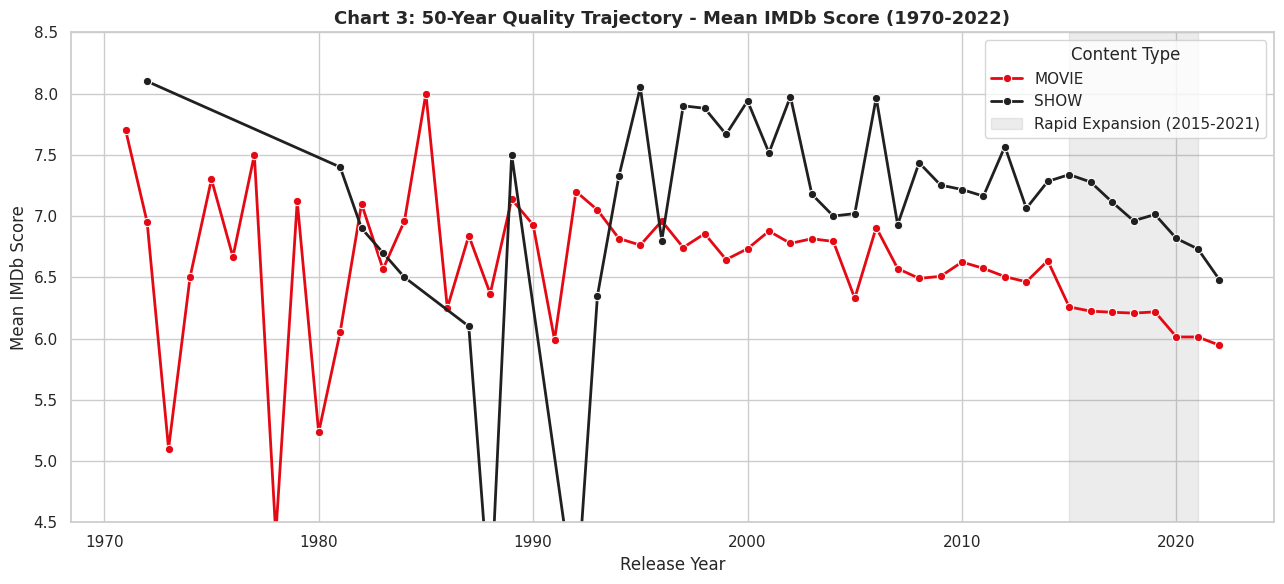

In [ ]:
# filtering to 1970-2022 only
# also removing anything without an imdb score because groupby mean will mess up otherwise
subset = netflix[netflix["release_year"] >= 1970]
subset = subset[subset["release_year"] <= 2022]
subset = subset[subset["imdb_score"].notna()]

print("rows left after filter:", len(subset))

# getting average score per year and per content type
# so if 2010 had 30 movies their average score is one value
avg_by_year = subset.groupby(["release_year", "type"])["imdb_score"].mean()
avg_by_year = avg_by_year.reset_index()

# quick look
print(avg_by_year.tail())

# ---------- plot ----------
fig, ax = plt.subplots(figsize=(13, 6))

sns.lineplot(
    data=avg_by_year,
    x="release_year",
    y="imdb_score",
    hue="type",
    marker="o",
    palette={"MOVIE": "#E50914", "SHOW": "#221F1F"},
    linewidth=2,
    ax=ax
)

# this band shows when netflix was adding content really aggressively
# quality dropped here for movies so wanted to highlight it
ax.axvspan(2015, 2021, color="gray", alpha=0.15, label="Rapid Expansion (2015-2021)")

ax.set_title("Chart 3: 50-Year Quality Trajectory - Mean IMDb Score (1970-2022)", fontsize=13, fontweight="bold")
ax.set_xlabel("Release Year")
ax.set_ylabel("Mean IMDb Score")
ax.set_ylim(4.5, 8.5)
ax.legend(title="Content Type")

plt.tight_layout()
plt.show()

A. Prem Steiven Doss

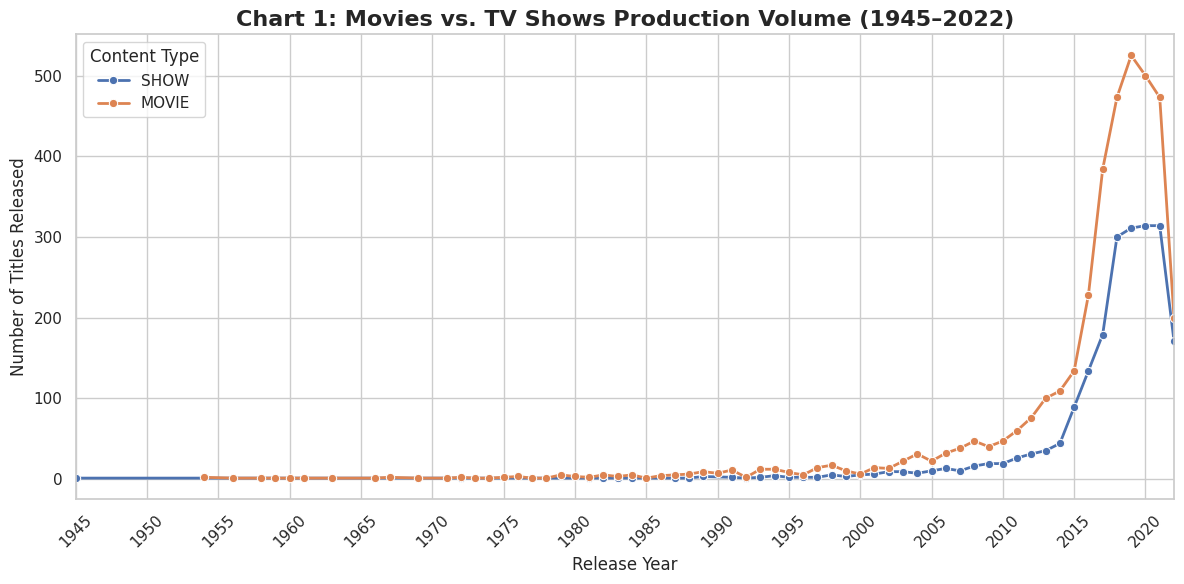

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reading the Netflix titles CSV file
titles = pd.read_csv("titles.csv")

# Taking only the titles released between 1945 and 2022
historical_data = titles[
    (titles["release_year"] >= 1945) &
    (titles["release_year"] <= 2022)
]

# Counting the number of movies and shows released each year
production_data = (
    historical_data
    .groupby(["release_year", "type"])
    .size()
    .reset_index(name="total_released")
)

# Setting a clean style for the chart
sns.set_theme(style="whitegrid")

# Creating the chart
plt.figure(figsize=(12, 6))

# Drawing separate lines for movies and shows
sns.lineplot(
    data=production_data,
    x="release_year",
    y="total_released",
    hue="type",
    marker="o",
    linewidth=2
)

# Adding the chart title
plt.title(
    "Chart 1: Movies vs. TV Shows Production Volume (1945–2022)",
    fontsize=16,
    fontweight="bold"
)

# Adding names to the axes
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles Released", fontsize=12)

# Keeping the timeline between 1945 and 2022
plt.xlim(1945, 2022)

# Showing selected years so the x-axis is easy to read
plt.xticks(range(1945, 2023, 5), rotation=45)

# Adding a legend
plt.legend(
    title="Content Type"
)

# Adjusting the layout
plt.tight_layout()

# Showing the final chart
plt.show()

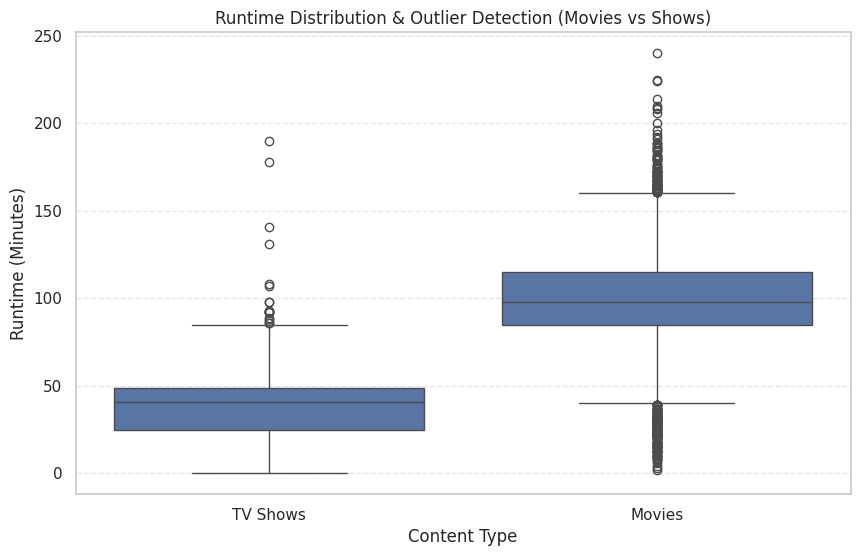

In [ ]:
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the uploaded Netflix dataset
# Load the uploaded Netflix dataset
data = pd.read_csv("titles.csv")

# Select only the columns needed for this chart
runtime = data[["type", "runtime"]]

# Remove rows where runtime is missing
runtime = runtime.dropna()

# Convert runtime values into numbers
runtime["runtime"] = pd.to_numeric(
    runtime["runtime"],
    errors="coerce"
)

# Remove invalid runtime values
runtime = runtime.dropna()

# Change the names to make the chart easier to understand
runtime["type"] = runtime["type"].replace({
    "MOVIE": "Movies",
    "SHOW": "TV Shows"
})

# Create the boxplot
plt.figure(figsize=(10, 6))

sns.boxplot(
    x="type",
    y="runtime",
    data=runtime
)

# Add the chart title
plt.title("Runtime Distribution & Outlier Detection (Movies vs Shows)")

# Add axis labels
plt.xlabel("Content Type")
plt.ylabel("Runtime (Minutes)")

# Add grid lines
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display the chart
plt.show()

In [ ]:
# Install any missing library
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Make plots look clean
sns.set_theme(style="whitegrid")

print("Libraries loaded successfully!")

Libraries loaded successfully!


***TALENT IMPACT, ENGAGEMENT MECHANICS & STATISTICAL CORRELATIONS***

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# select the columns needed for correlation
corr_data = netflix_raw[
    ["imdb_score", "imdb_votes", "tmdb_score", "tmdb_popularity"]
]

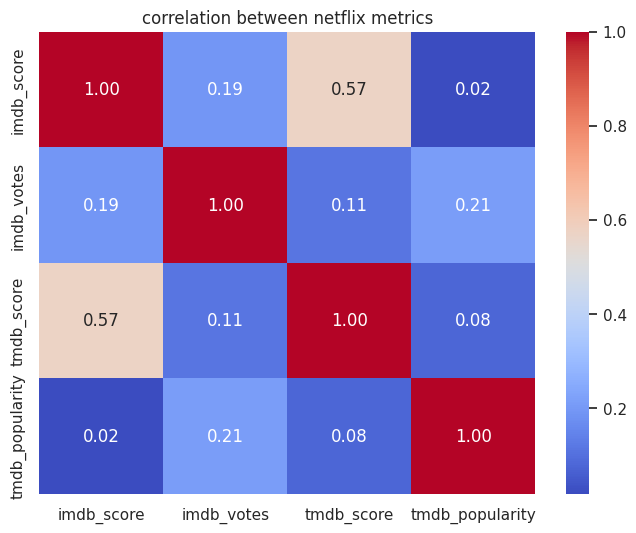

In [ ]:
# correlation between the main columns
data = netflix_raw[["imdb_score", "imdb_votes", "tmdb_score", "tmdb_popularity"]]

corr = data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("correlation between netflix metrics")
plt.show()

Pearson correlation: 0.018
P-value: 0.19855498919807907


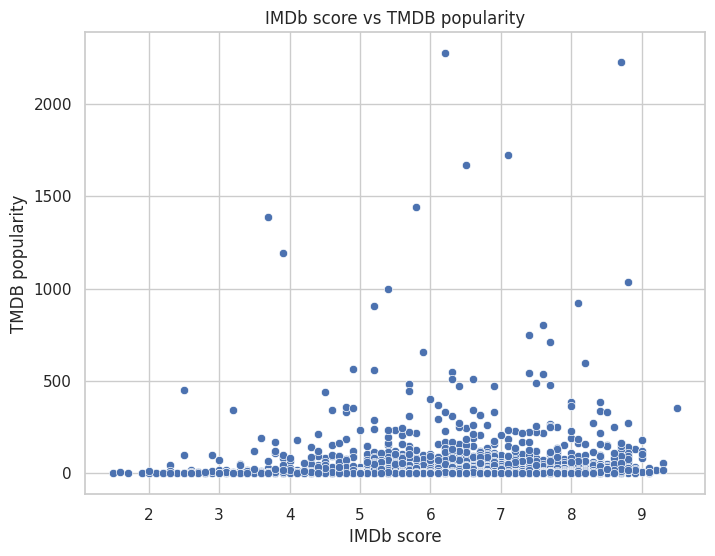

In [ ]:
#  check IMDb score and TMDB popularity, dropping any missing rows
data = netflix_raw[["imdb_score", "tmdb_popularity"]].dropna()

# find pearson correlation and print the results
r, p = pearsonr(data["imdb_score"], data["tmdb_popularity"])
print("Pearson correlation:", round(r, 3))
print("P-value:", p)

#  create a simple scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x="imdb_score",
    y="tmdb_popularity"
)

# add titles and labels
plt.title("IMDb score vs TMDB popularity")
plt.xlabel("IMDb score")
plt.ylabel("TMDB popularity")

plt.show()

In [ ]:
# hypothesis test
if p < 0.05:
    print("reject H0")
    print("there is a significant relationship.")
else:
    print("fail to reject H0")
    print("there is no significant relationship.")

fail to reject H0
there is no significant relationship.


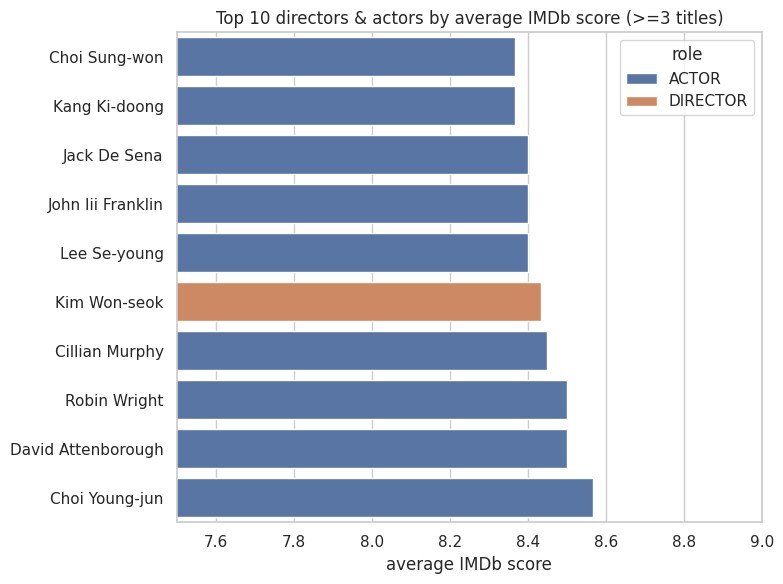

In [ ]:
# top 10 directors and actors

credits = credits_raw[["id", "name", "role"]]

talent = credits.merge(
    netflix_raw[["id", "imdb_score"]],
    on="id",
    how="inner"
)

counts = talent.groupby(["name", "role"]).size().reset_index(name="title_count")

scores = talent.groupby(["name", "role"])["imdb_score"].mean().reset_index()
scores = scores.rename(columns={"imdb_score": "avg_imdb_score"})

top10 = counts.merge(scores, on=["name", "role"])

top10 = top10[top10["title_count"] >= 3]

top10 = top10.sort_values("avg_imdb_score", ascending=False).head(10)



#to plot

plt.figure(figsize=(8, 6))

sns.barplot(
    data=top10.sort_values("avg_imdb_score"),
    x="avg_imdb_score",
    y="name",
    hue="role",
    dodge=False
)

plt.title("Top 10 directors & actors by average IMDb score (>=3 titles)")
plt.xlabel("average IMDb score")
plt.ylabel("")

plt.xlim(7.5, 9)
plt.tight_layout()
plt.savefig("chart3_talent_leaderboard.png", dpi=150)
plt.show()

In [ ]:
# other correlations with IMDb score
print("\ncorrelation with IMDb score:")

print("IMDb votes:",
      round(netflix_raw["imdb_score"].corr(netflix_raw["imdb_votes"]), 2))

print("TMDB score:",
      round(netflix_raw["imdb_score"].corr(netflix_raw["tmdb_score"]), 2))

print("TMDB popularity:",
      round(netflix_raw["imdb_score"].corr(netflix_raw["tmdb_popularity"]), 2))


correlation with IMDb score:
IMDb votes: 0.19
TMDB score: 0.57
TMDB popularity: 0.02


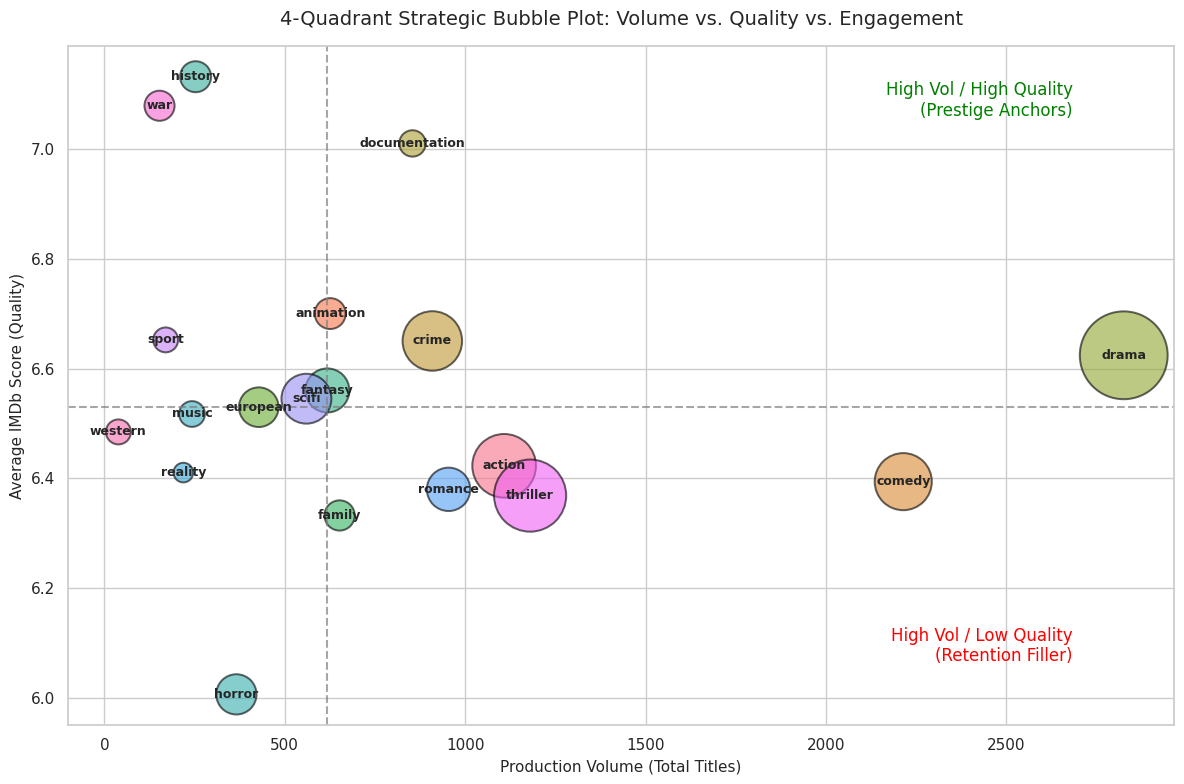

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# load the raw data
df = pd.read_csv("titles.csv")

# unpack those messy kaggle genre lists again
def fix_genres(val):
    if pd.notna(val) and str(val).startswith("["):
        return ast.literal_eval(val)
    return []

df['genre_list'] = df['genres'].apply(fix_genres)

# explode so each genre gets its own row (a movie with 3 genres counts for all 3)
df_genres = df.explode('genre_list').dropna(subset=['genre_list', 'imdb_score', 'imdb_votes'])

# crunch the numbers for the bubbles
bubble_data = df_genres.groupby('genre_list').agg(
    volume=('id', 'count'),            # x-axis: how many titles
    avg_quality=('imdb_score', 'mean'),# y-axis: quality
    total_votes=('imdb_votes', 'sum')  # bubble size: engagement depth
).reset_index()

# filter out the tiny niche genres so the graph isn't a crowded mess
bubble_data = bubble_data[bubble_data['volume'] > 30]

# set up the canvas
plt.figure(figsize=(12, 8))
sns.set_style("whitegrid")

# draw the actual bubbles
sns.scatterplot(
    data=bubble_data,
    x='volume',
    y='avg_quality',
    size='total_votes',
    sizes=(200, 4000),     # min and max bubble sizes (tweak these if they look too huge)
    hue='genre_list',      # gives every bubble a different color
    alpha=0.6,             # makes them see-through so overlapping looks good
    edgecolor="black",
    legend=False           # turning this off because the labels do the work
)

# paste the genre names directly onto the bubbles
for i in range(len(bubble_data)):
    plt.text(
        bubble_data['volume'].iloc[i],
        bubble_data['avg_quality'].iloc[i],
        bubble_data['genre_list'].iloc[i],
        ha='center',
        va='center',
        fontsize=9,
        weight='bold'
    )

# draw the crosshairs to create the 4 strategic quadrants
# placing the lines right at the median averages so it splits perfectly
plt.axvline(bubble_data['volume'].median(), color='gray', linestyle='--', alpha=0.7)
plt.axhline(bubble_data['avg_quality'].median(), color='gray', linestyle='--', alpha=0.7)

# finish up the formatting
plt.title("4-Quadrant Strategic Bubble Plot: Volume vs. Quality vs. Engagement", fontsize=14, pad=15)
plt.xlabel("Production Volume (Total Titles)", fontsize=11)
plt.ylabel("Average IMDb Score (Quality)", fontsize=11)

# add quadrant labels in the corners just for extra points on the report
plt.text(bubble_data['volume'].max() * 0.95, bubble_data['avg_quality'].max() * 0.99,
         "High Vol / High Quality\n(Prestige Anchors)", color='green', ha='right')
plt.text(bubble_data['volume'].max() * 0.95, bubble_data['avg_quality'].min() * 1.01,
         "High Vol / Low Quality\n(Retention Filler)", color='red', ha='right')

plt.tight_layout()
plt.show()